# Normalised structural IC per ontology

Distribution of `ic = IC / ln N = 1 - ln c / ln N` (c = descendants + 1, N = nodes in the restricted graph)
over **all terms** of each association-target ontology, as stored in `entity.ic`.

Question: is `ic` on a comparable scale across ontologies (notes/WEIGHTED_RANKING_PLAN.md, cross-ontology comparability)?

- Every leaf has `ic = 1.00` exactly; they form the last histogram bar on their own, since no non-leaf term reaches that bin.
- The largest non-leaf value is `1 - ln 2 / ln N`, so the gap below 1.0 depends on N.
- Both plots use a log y-axis: fewer than 1% of terms lie below any crossover.
- Dashed lines: **provisional, agent-only** crossovers from `notes/IC_THRESHOLD_ANALYSIS.md` §6 (shaded band where only a range is known).

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from textmining.enums import HitType
from textmining.ontology import OntologyGraph
from textmining.resources import ONTOLOGY_SOURCES

ENTITY_TYPES = (HitType.DISEASE, HitType.BIOLOGICAL_PROCESS, HitType.CELL,
                HitType.PATHWAY, HitType.TISSUE)

# notes/IC_THRESHOLD_ANALYSIS.md §6, agents only; (lo, hi). GO-BP is a lower bound (0.50+).
CROSSOVER = {
    HitType.DISEASE: (0.28, 0.28),
    HitType.CELL: (0.25, 0.25),
    HitType.TISSUE: (0.27, 0.27),
    HitType.PATHWAY: (0.35, 0.46),
    HitType.BIOLOGICAL_PROCESS: (0.50, 0.50),
}

In [2]:
def ic_table(entity_type: HitType) -> pd.DataFrame:
    graph = OntologyGraph.from_source(ONTOLOGY_SOURCES[entity_type])
    g, log_n = graph._rel_subgraph, math.log(graph.node_num)
    rows = []
    for idx in g.node_indices():
        ic = max(0.0, graph.compute_ic_from_index(idx) / log_n)
        rows.append((entity_type.name, graph.map_idx_to_external_id(idx),
                     g[idx].get('name', ''), g.out_degree(idx) == 0, ic))
    return pd.DataFrame(rows, columns=['ontology', 'term_id', 'name', 'is_leaf', 'ic'])

df = pd.concat([ic_table(t) for t in ENTITY_TYPES], ignore_index=True)
df.groupby('ontology').size()

ontology
BIOLOGICAL_PROCESS    23974
CELL                   3325
DISEASE               31558
PATHWAY                2601
TISSUE                 2583
dtype: int64

In [3]:
def summary(group: pd.DataFrame) -> pd.Series:
    etype = HitType[group.name]
    n = len(group)
    inner = group.loc[~group.is_leaf, 'ic']
    lo, _ = CROSSOVER[etype]
    return pd.Series({
        'N': n,
        'leaf share': group.is_leaf.mean(),
        'max non-leaf ic': 1 - math.log(2) / math.log(n),
        'non-leaf q25': inner.quantile(0.25),
        'non-leaf median': inner.median(),
        'non-leaf q75': inner.quantile(0.75),
        'crossover': lo,
        'share below crossover': (group.ic < lo).mean(),
    })

stats = df.groupby('ontology').apply(summary, include_groups=False)
stats.style.format({'N': '{:,.0f}', 'leaf share': '{:.1%}', 'share below crossover': '{:.1%}'},
                   precision=3)

,N,leaf share,max non-leaf ic,non-leaf q25,non-leaf median,non-leaf q75,crossover,share below crossover
ontology,,,,,,,,
BIOLOGICAL_PROCESS,"23,974",55.0%,0.931,0.782,0.891,0.891,0.500,0.9%
CELL,"3,325",63.6%,0.915,0.694,0.802,0.865,0.250,0.5%
DISEASE,"31,558",75.4%,0.933,0.760,0.845,0.894,0.280,0.1%
PATHWAY,"2,601",59.6%,0.912,0.753,0.860,0.860,0.350,0.5%
TISSUE,"2,583",65.1%,0.912,0.707,0.824,0.912,0.270,0.3%


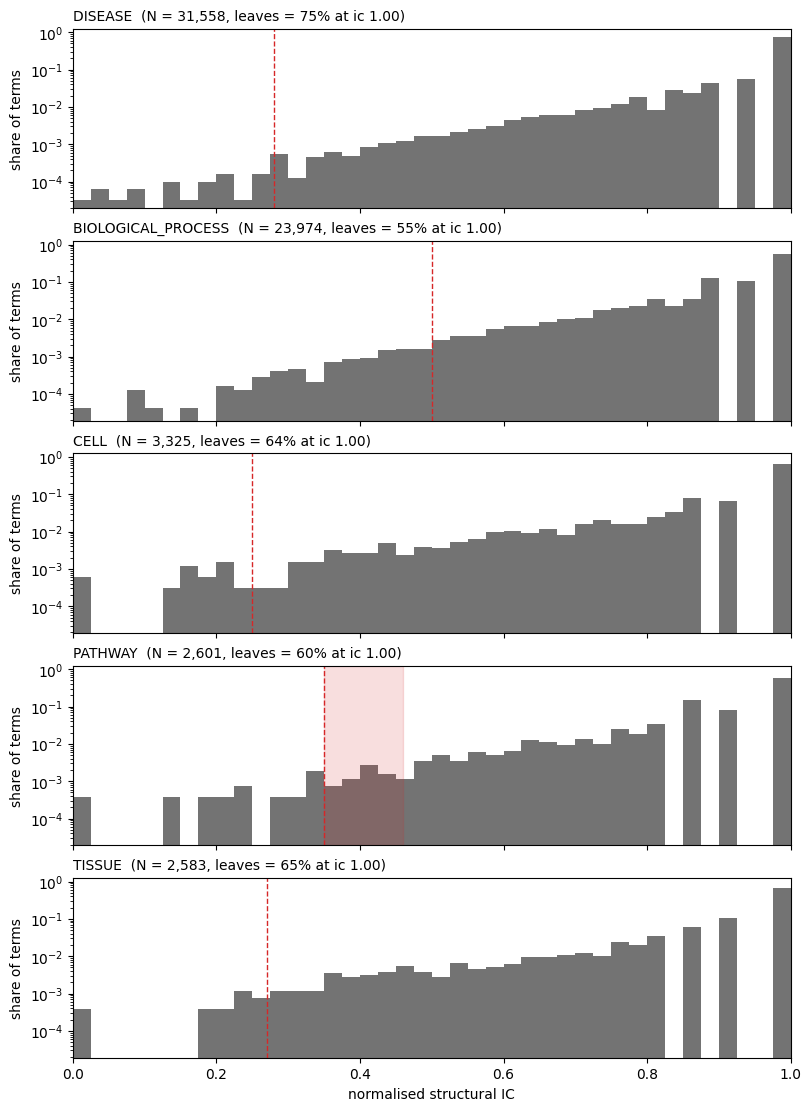

In [4]:
bins = np.arange(0, 1.0001, 0.025)
fig, axes = plt.subplots(len(ENTITY_TYPES), 1, figsize=(8, 2.2 * len(ENTITY_TYPES)),
                         sharex=True, sharey=True, constrained_layout=True)

for ax, etype in zip(axes, ENTITY_TYPES):
    group = df[df.ontology == etype.name]
    # Weighted by 1 / all terms, so bar heights are comparable across ontologies of different size.
    ax.hist(group.ic, bins=bins, weights=np.full(len(group), 1 / len(group)), color='0.45')
    lo, hi = CROSSOVER[etype]
    if hi > lo:
        ax.axvspan(lo, hi, color='tab:red', alpha=0.15)
    ax.axvline(lo, color='tab:red', ls='--', lw=1)
    ax.set_title(f'{etype.name}  (N = {len(group):,}, leaves = {group.is_leaf.mean():.0%} at ic 1.00)',
                 loc='left', fontsize=10)
    ax.set_yscale('log')  # < 1% of terms lie below the crossovers, while leaves are 55-75%
    ax.set_ylabel('share of terms')

axes[-1].set_xlabel('normalised structural IC')
axes[-1].set_xlim(0, 1)
plt.show()

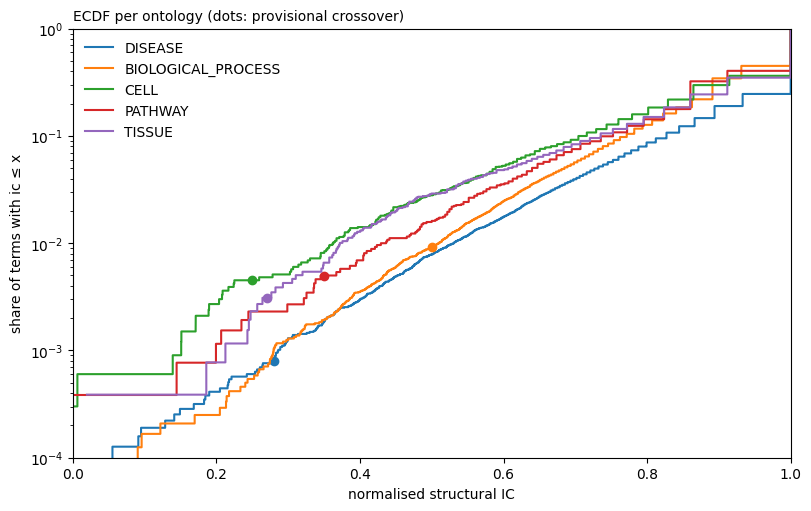

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

for etype in ENTITY_TYPES:
    ic = np.sort(df.loc[df.ontology == etype.name, 'ic'].to_numpy())
    ecdf = np.arange(1, len(ic) + 1) / len(ic)
    line, = ax.step(ic, ecdf, where='post', label=etype.name)
    lo, _ = CROSSOVER[etype]
    ax.plot(lo, np.searchsorted(ic, lo, side='left') / len(ic), 'o', color=line.get_color())

ax.set_xlim(0, 1)
ax.set_yscale('log')  # the low-IC tail is the interesting part and holds < 1% of terms
ax.set_ylim(1e-4, 1)
ax.set_xlabel('normalised structural IC')
ax.set_ylabel('share of terms with ic ≤ x')
ax.set_title('ECDF per ontology (dots: provisional crossover)', loc='left', fontsize=10)
ax.legend(frameon=False)
plt.show()

## IC vs. evidence score of associated terms

Associations of one ontology in `atlas.db`, restricted to the miRNAs selected by `ORGANISM`
(miRBase prefix, `None` = all) and `INCLUDE_FAMILIES` (families carry no organism). `atlas.db`
predates `entity.ic`, so `ic` is joined from the table above by accession.

Rows are score bands (score 1 = one article with one co-occurrence), columns are IC bands of 0.05.
The last column holds only leaves (no non-leaf term reaches 0.95). Above each column: how many
distinct terms it contains; columns with a few terms show those terms, not a trend.

- **Left: counts.** Where the associations are.
- **Right: share within each IC column.** The score distribution *given* the IC band, so columns of
  very different size can be compared: if score did not depend on IC, all columns would look alike.

In [6]:
from textmining.db.connect import open_readonly

PLOT_TYPE = HitType.DISEASE
ORGANISM = 'hsa'          # None = all organisms
INCLUDE_FAMILIES = True

with open_readonly(immutable=True) as con:
    assoc = pd.read_sql_query(
        """SELECT e.accession AS term_id, a.score
           FROM association a
           JOIN entity e ON e.id = a.term_entity_id
           JOIN entity m ON m.id = a.mirna_entity_id
           WHERE a.term_type = :tt
             AND (:org IS NULL OR m.organism = :org
                  OR (:fam AND m.reference_level = 'family'))""",
        con, params={'tt': PLOT_TYPE.value, 'org': ORGANISM, 'fam': INCLUDE_FAMILIES})

POPULATION = (ORGANISM or 'all organisms') + (' + families' if ORGANISM and INCLUDE_FAMILIES else '')

terms = df.loc[df.ontology == PLOT_TYPE.name, ['term_id', 'ic', 'is_leaf']]
assoc = assoc.merge(terms, on='term_id', how='left', validate='many_to_one')
print(f'{len(assoc):,} associations, {assoc.term_id.nunique():,} distinct terms, '
      f'{assoc.ic.isna().sum():,} without ic (term not in current graph)')
assoc = assoc.dropna(subset=['ic'])

769,889 associations, 4,740 distinct terms, 0 without ic (term not in current graph)


In [7]:
from matplotlib.colors import LogNorm

ic_edges = np.round(np.arange(0, 1.0001, 0.05), 2)
ic_band = pd.cut(assoc.ic, ic_edges, include_lowest=True)
n_terms = assoc.groupby(ic_band, observed=False).term_id.nunique().to_numpy()


def compact(n):
    return f'{n / 1000:.0f}k' if n >= 10_000 else f'{n / 1000:.1f}k' if n >= 1000 else f'{n:d}'


def heatmap(ax, values, y_edges, labels, norm, title, y_label):
    masked = np.ma.masked_equal(values, 0)
    mesh = ax.pcolormesh(ic_edges, y_edges, masked, cmap='viridis', norm=norm)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if values[i, j] > 0:
                x, y = (ic_edges[j] + ic_edges[j + 1]) / 2, y_edges[i] + 0.5
                dark = np.clip(norm(values[i, j]), 0, 1) < 0.6
                ax.text(x, y, labels[i][j], ha='center', va='center', fontsize=6,
                        color='white' if dark else 'black')
    top = ax.twiny()
    top.set_xlim(ax.get_xlim())
    top.set_xticks((ic_edges[:-1] + ic_edges[1:]) / 2, [compact(int(n)) for n in n_terms], fontsize=6)
    top.tick_params(length=0)
    top.set_xlabel('distinct terms in the IC band', fontsize=8)
    lo, _ = CROSSOVER[PLOT_TYPE]
    ax.axvline(lo, color='tab:red', ls='--', lw=1)
    ax.set_xticks(ic_edges[::2])
    ax.set_yticks(y_edges)
    ax.set_xlabel('normalised structural IC')
    ax.set_ylabel(y_label)
    ax.set_title(title, loc='left', fontsize=10)
    ax.set_facecolor('0.95')
    return mesh


def ic_heatmaps(values: pd.Series, name: str):
    """Counts and per-IC-column shares of `values` in bands of width 1."""
    y_edges = np.arange(math.floor(values.min()), math.floor(values.max()) + 2)
    y_band = pd.cut(values, y_edges, right=False)
    counts = pd.crosstab(y_band, ic_band, dropna=False).to_numpy()   # rows: value, columns: IC
    share = counts / np.maximum(counts.sum(axis=0, keepdims=True), 1)

    fig, (ax_n, ax_s) = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
    m = heatmap(ax_n, counts, y_edges, [[compact(int(v)) for v in row] for row in counts],
                LogNorm(1, counts.max()), f'{PLOT_TYPE.name} ({POPULATION}): associations per cell', name)
    fig.colorbar(m, ax=ax_n, label='associations (log)')
    m = heatmap(ax_s, share, y_edges, [[f'{v:.0%}' if v >= 0.005 else '<1%' for v in row] for row in share],
                # Log scale: columns with one or two terms reach 100% and would wash out the rest.
                LogNorm(1e-3, 1, clip=True), 'share of the IC column (red: provisional crossover)', name)
    fig.colorbar(m, ax=ax_s, label='share of associations in the IC band (log)')
    plt.show()

### Raw evidence score

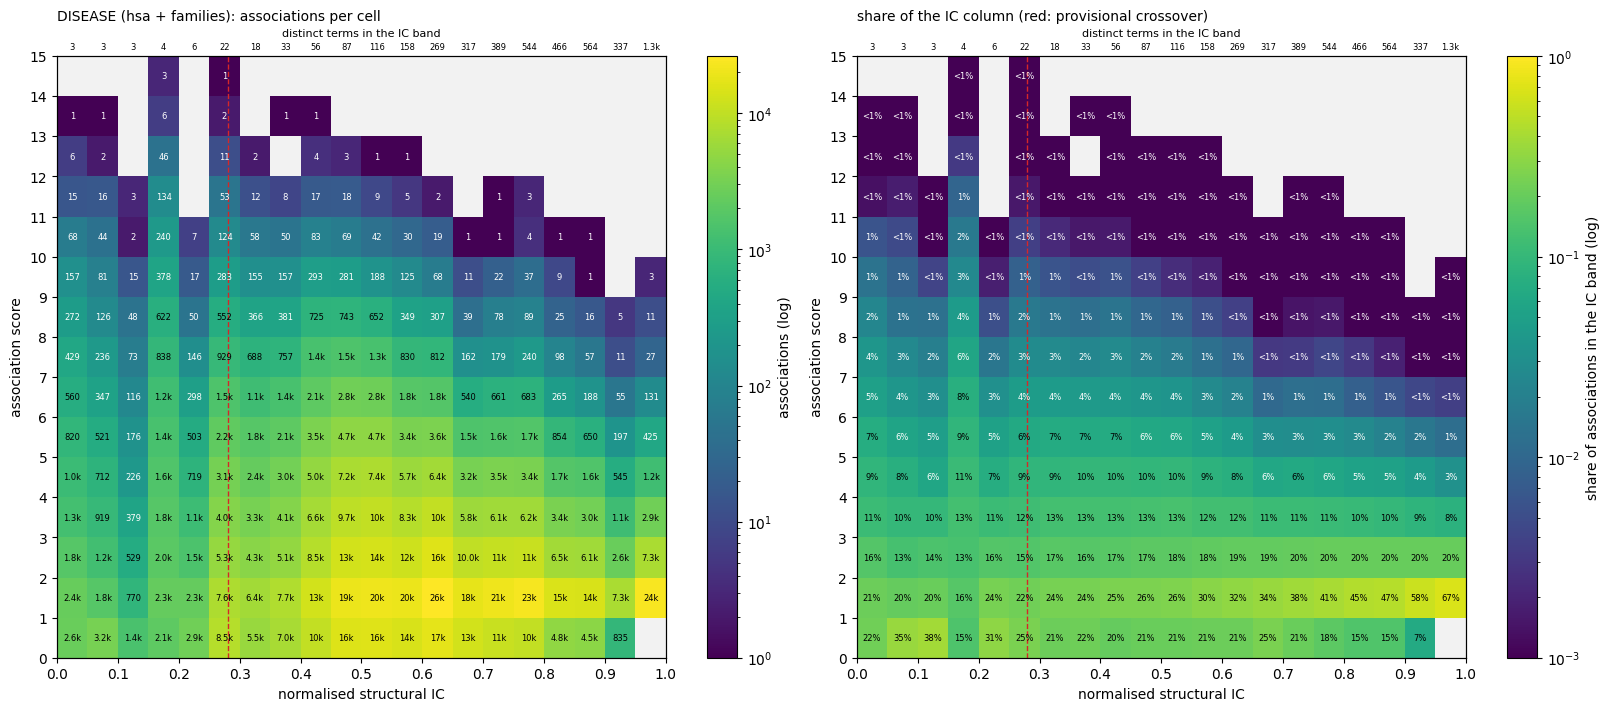

In [8]:
ic_heatmaps(assoc.score, 'association score')

### Weighted after the outer log: `score × ic`

The current plan (notes/WEIGHTED_RANKING_PLAN.md §2). Since `score = log2(1 + E)`, this ranks by `(1 + E)^ic`:
IC acts as an exponent on the evidence.

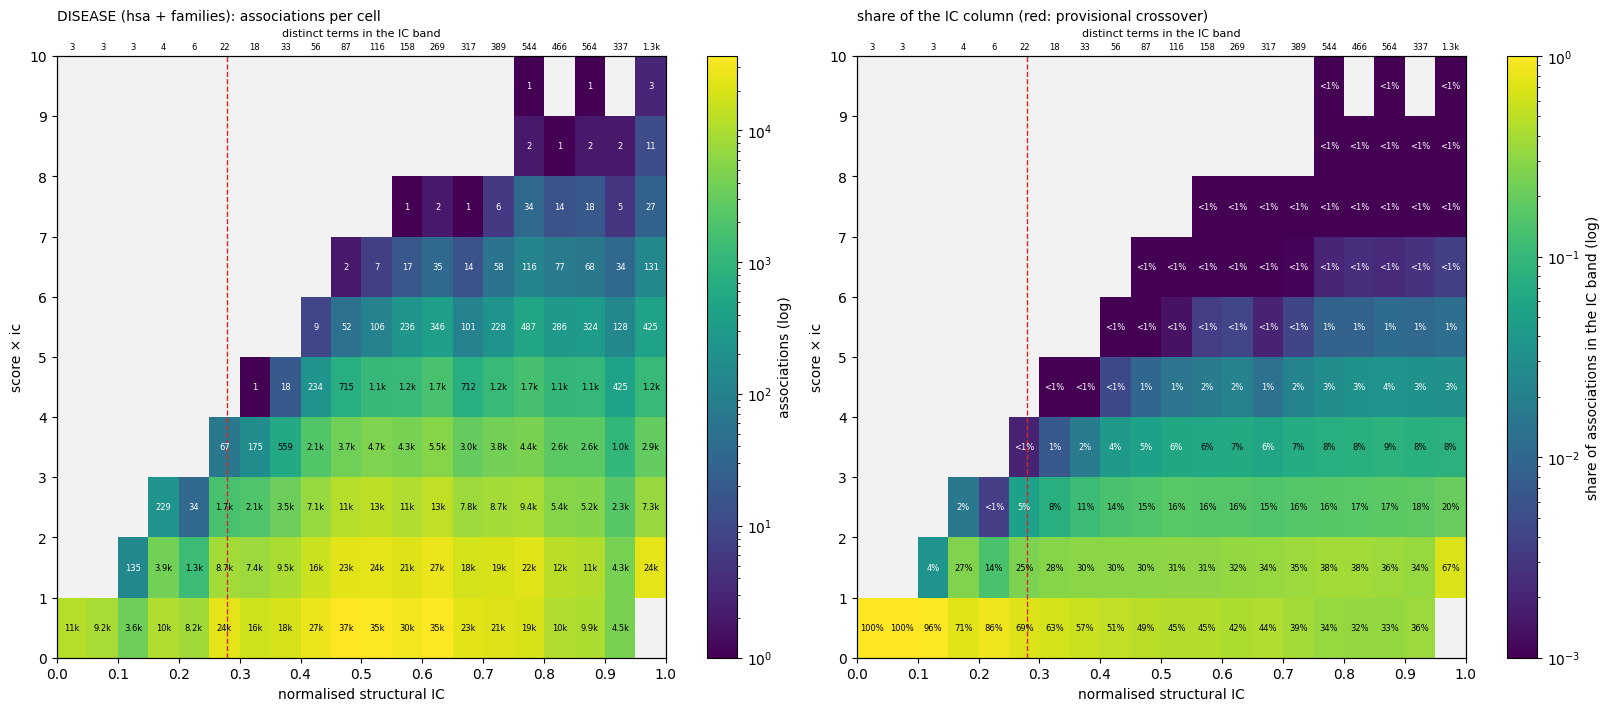

In [9]:
ic_heatmaps(assoc.score * assoc.ic, 'score × ic')

### Weighted before the outer log: `log2(1 + ic · E)`

`E = 2^score − 1` is the evidence mass inside the outer log (exact up to the 4-decimal rounding of the
score). IC discounts the evidence by a constant factor instead of acting as an exponent. This is not
the per-co-occurrence variant (IC inside the per-article log), which cannot be reconstructed from the
stored score.

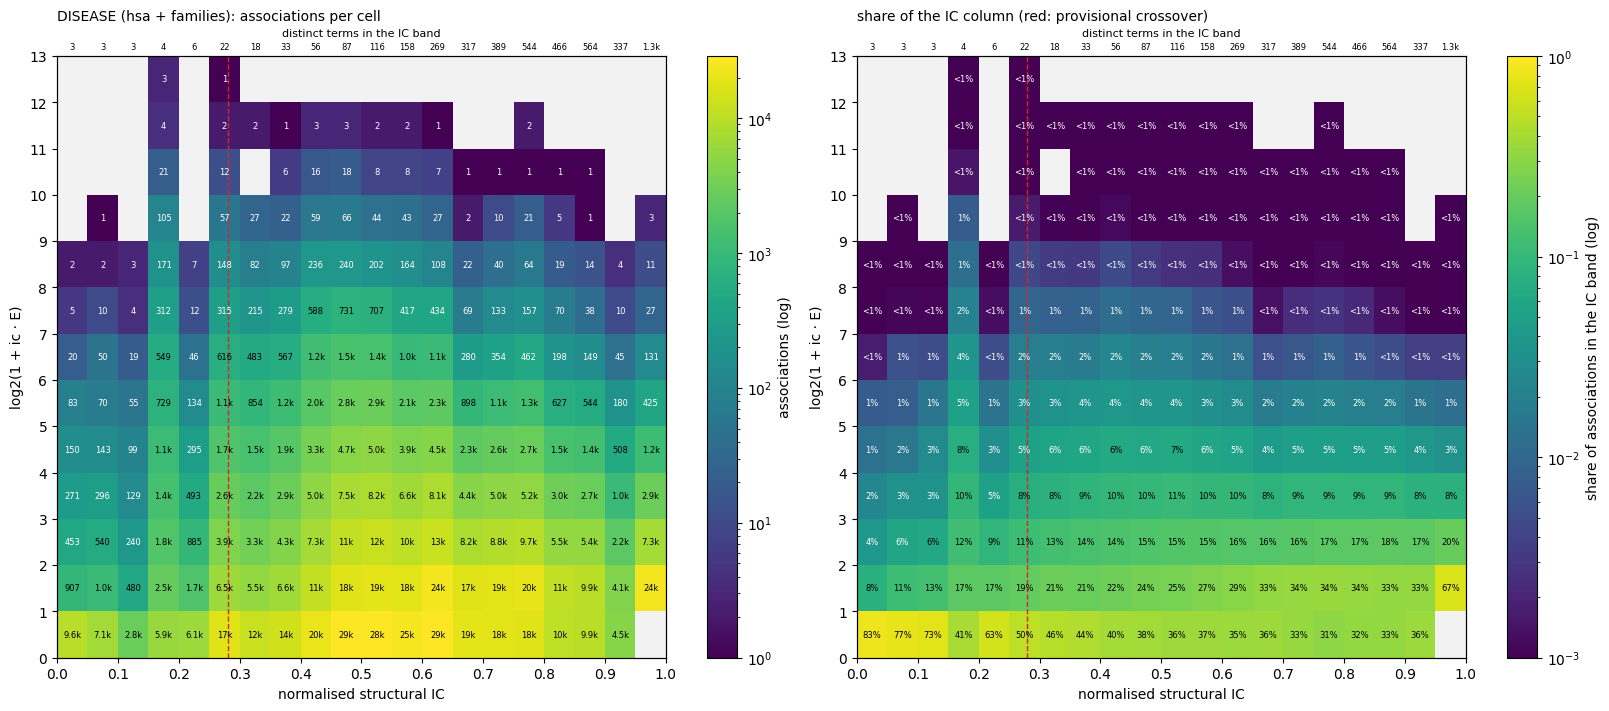

In [10]:
evidence_mass = np.power(2.0, assoc.score) - 1
ic_heatmaps(np.log2(1 + assoc.ic * evidence_mass), 'log2(1 + ic · E)')

### Weighted before the outer log with α = 2: `log2(1 + ic² · E)`

Same as above with a stronger discount: halving `ic` costs 4× the evidence instead of 2×.

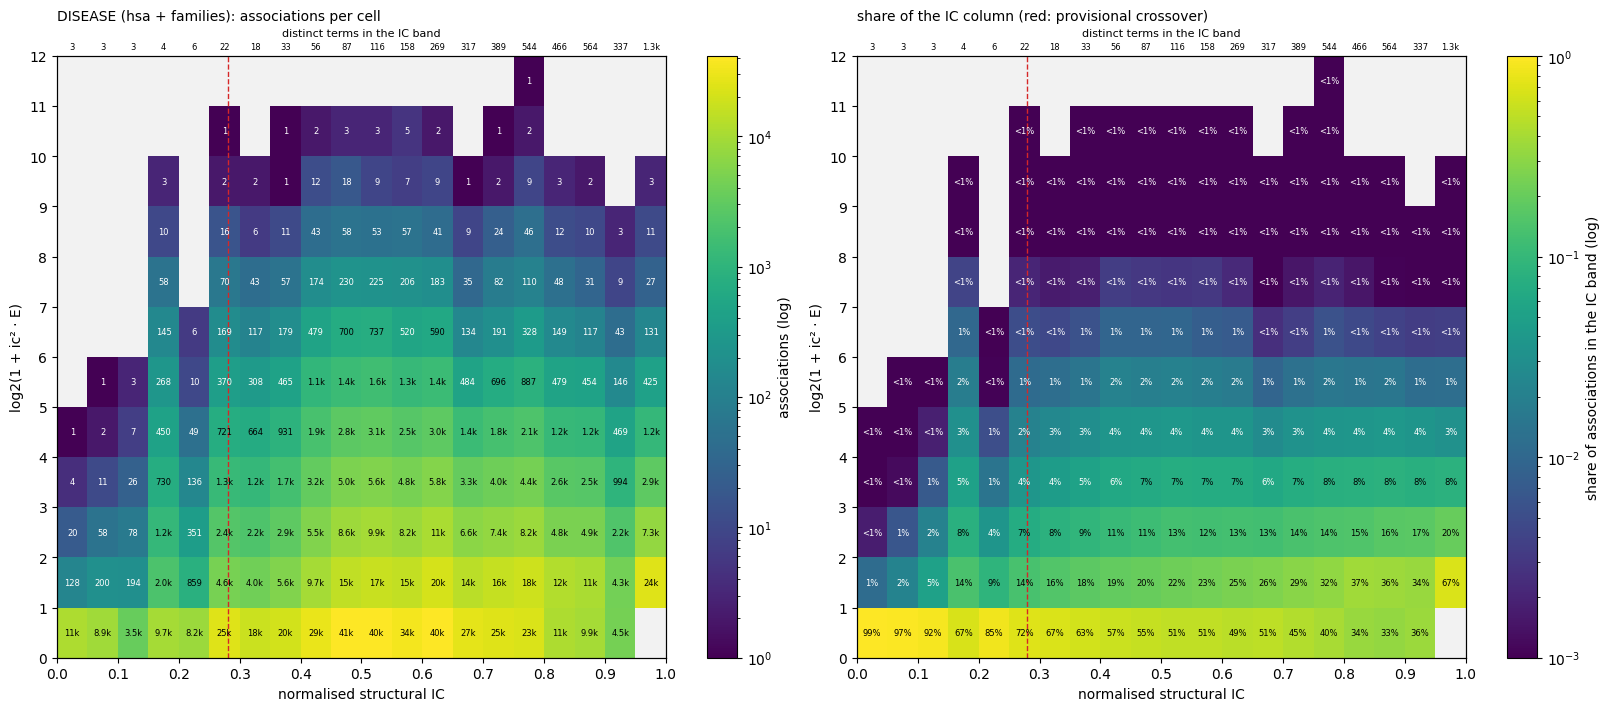

In [11]:
ic_heatmaps(np.log2(1 + assoc.ic ** 2 * evidence_mass), 'log2(1 + ic² · E)')

### Correlation of IC and score within IC bins

For each IC bin: Spearman correlation between the term's `ic` and the (weighted) association score, over
the associations in that bin. It shows whether, *locally*, more specific terms carry more or less evidence,
and how each weighting changes that.

- A bin needs at least `MIN_DISTINCT_IC` distinct IC values and `MIN_ASSOCIATIONS` associations; otherwise
  it is left empty (the leaf bin always is: every leaf has `ic = 1.00`).
- Associations of one term share one `ic`, so the correlation is driven by a few distinct IC values in
  sparse bins. The numbers above each bar are distinct IC values / distinct terms.
- `score × ic` and the weighted variants contain `ic` themselves, so part of their within-bin correlation
  is built in by construction. That part is small in narrow bins, where `ic` barely varies, except in
  the first bin: roots have `ic = 0`, so every weighted value there is 0 and the correlation is trivially high.

/mnt/extstudtemp/mitsopoulos/Text-Mining/.venv/lib64/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


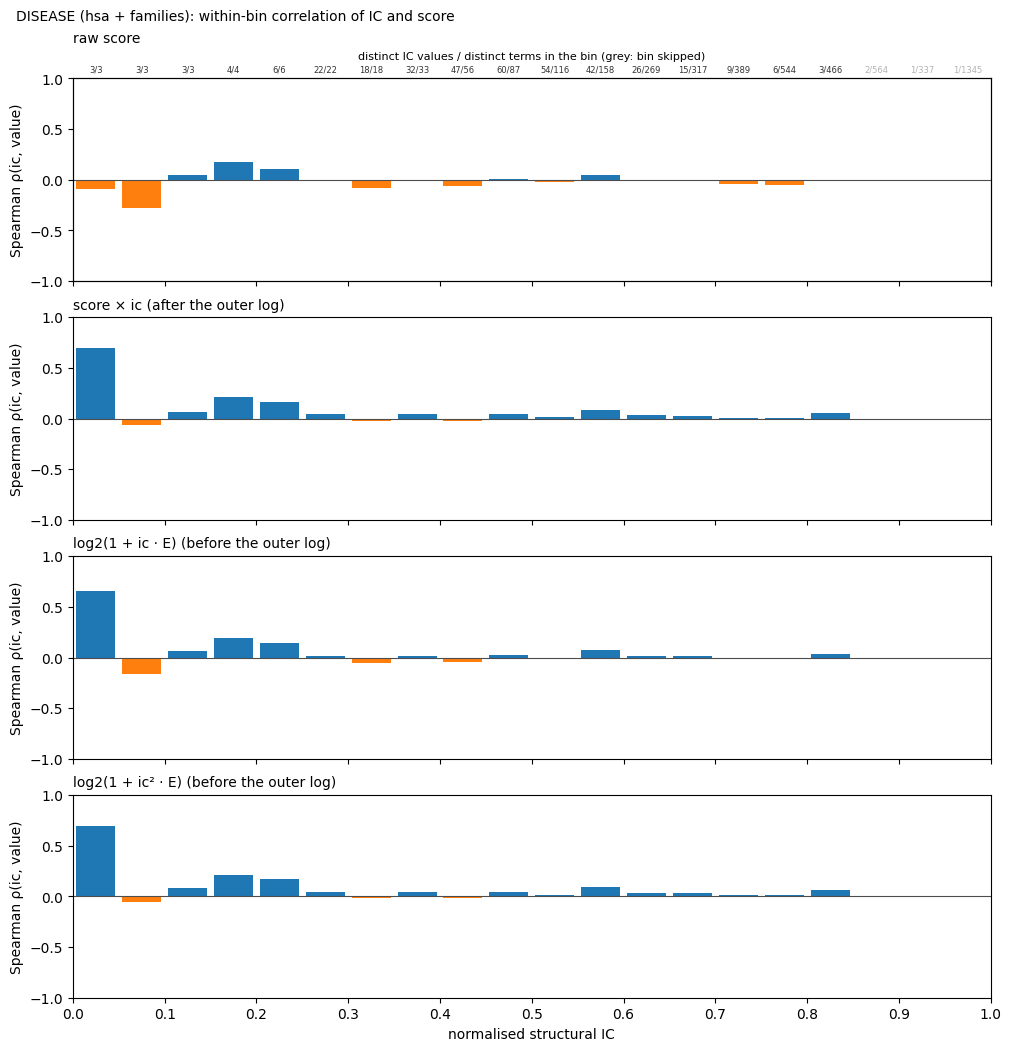

In [12]:
CORR_BIN = 0.05
MIN_DISTINCT_IC = 3
MIN_ASSOCIATIONS = 30

weighted = {
    'raw score': assoc.score,
    'score × ic (after the outer log)': assoc.score * assoc.ic,
    'log2(1 + ic · E) (before the outer log)': np.log2(1 + assoc.ic * evidence_mass),
    'log2(1 + ic² · E) (before the outer log)': np.log2(1 + assoc.ic ** 2 * evidence_mass),
}

corr_edges = np.round(np.arange(0, 1.0001, CORR_BIN), 3)
corr_band = pd.cut(assoc.ic, corr_edges, include_lowest=True)
mids = (corr_edges[:-1] + corr_edges[1:]) / 2
groups = assoc.groupby(corr_band, observed=False)
n_ic = groups.ic.nunique().to_numpy()
n_term = groups.term_id.nunique().to_numpy()
n_assoc = groups.size().to_numpy()
usable = (n_ic >= MIN_DISTINCT_IC) & (n_assoc >= MIN_ASSOCIATIONS)

fig, axes = plt.subplots(len(weighted), 1, figsize=(10, 2.6 * len(weighted)),
                         sharex=True, sharey=True, constrained_layout=True)
for ax, (name, values) in zip(axes, weighted.items()):
    frame = pd.DataFrame({'ic': assoc.ic, 'v': values, 'band': corr_band})
    rho = frame.groupby('band', observed=False).apply(
        lambda g: g.ic.corr(g.v, method='spearman'), include_groups=False).to_numpy()
    rho = np.where(usable, rho, np.nan)
    ax.bar(mids, rho, width=CORR_BIN * 0.85, color=np.where(rho >= 0, 'tab:blue', 'tab:orange'))
    ax.axhline(0, color='0.3', lw=0.8)
    ax.set_title(name, loc='left', fontsize=10)
    ax.set_ylabel('Spearman ρ(ic, value)')
axes[0].set_ylim(-1, 1)
axes[-1].set_xticks(corr_edges[::2])
axes[-1].set_xlim(0, 1)
top = axes[0].twiny()
top.set_xlim(0, 1)
top.set_xticks(mids, [f'{i}/{t}' for i, t in zip(n_ic, n_term)], fontsize=6)
for label, ok in zip(top.get_xticklabels(), usable):
    label.set_color('0.2' if ok else '0.7')
top.tick_params(length=0)
top.set_xlabel('distinct IC values / distinct terms in the bin (grey: bin skipped)', fontsize=8)
axes[-1].set_xlabel('normalised structural IC')
fig.suptitle(f'{PLOT_TYPE.name} ({POPULATION}): within-bin correlation of IC and score',
             fontsize=10, x=0.01, ha='left')
plt.show()